# 2. Compréhension des données (Data Understanding)

## 2.1. Importation des bibliothèques

Cette étape consiste à importer les bibliothèques Python
nécessaires au chargement, à la manipulation et à la visualisation
des données.

In [10]:
# Manipulation des données
import pandas as pd
import numpy as np

# Visualisation des données
import matplotlib.pyplot as plt
import seaborn as sns

# Gestion des chemins et fichiers
from pathlib import Path

# Configuration de l'affichage
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:.2f}".format)

# Configuration des graphiques
sns.set_theme(style="whitegrid")

print("Les bibliothèques ont été importées avec succès.")

Les bibliothèques ont été importées avec succès.


In [ ]:
## 2.2. Chargement du jeu de données

Le fichier Online Retail II est fourni au format Excel.

Il contient deux feuilles correspondant à deux périodes :
- Year 2009-2010
- Year 2010-2011

Nous allons charger les deux feuilles puis les regrouper
dans un seul DataFrame afin de disposer de l'ensemble
des transactions.

In [7]:
from pathlib import Path

# Si le notebook est dans le dossier 'notebooks', on remonte d'un niveau vers la racine
RACINE_PROJET = Path.cwd().parent
chemin_fichier = RACINE_PROJET / "data" / "raw" / "Copie de online_retail_II.xlsx"

# Vérification
if not chemin_fichier.exists():
  # Cas de secours si vous exécutez le notebook depuis la racine du projet
  chemin_fichier = (
      Path.cwd() / "data" / "raw" / "online_retail_II.xlsx"
  )

if not chemin_fichier.exists():
  raise FileNotFoundError(f"Fichier introuvable : {chemin_fichier.resolve()}")

print("Fichier trouvé avec succès :", chemin_fichier.resolve())

Fichier trouvé avec succès : C:\Users\Lenovo\Documents\online-retail-ii-customer-segmentation\data\raw\Copie de online_retail_II.xlsx


In [8]:
# Charger toutes les feuilles du fichier Excel
feuilles = pd.read_excel(
    chemin_fichier,
    sheet_name=None,
    engine="openpyxl"
)

# Afficher les noms des feuilles
print("Feuilles disponibles dans le fichier :")

for nom_feuille in feuilles.keys():
    print("-", nom_feuille)

Feuilles disponibles dans le fichier :
- Year 2009-2010
- Year 2010-2011


In [12]:
# Regrouper les feuilles dans un seul DataFrame
df = pd.concat(
    feuilles.values(),
    ignore_index=True
)

print("Chargement terminé.")
print("Nombre total de transactions :", len(df))

Chargement terminé.
Nombre total de transactions : 1067371


## 2.3. Exploration de la structure générale

Cette étape permet d'obtenir une première vue du jeu de données,
de vérifier ses dimensions et d'identifier ses différentes variables.

In [13]:
# Afficher les cinq premières lignes
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.00,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.00,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.00,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.00,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.00,United Kingdom


In [14]:
# Afficher les cinq dernières lignes
df.tail()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
1067366,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.00,France
1067367,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.00,France
1067368,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.00,France
1067369,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.00,France
1067370,581587,POST,POSTAGE,1,2011-12-09 12:50:00,18.00,12680.00,France


In [15]:
# Afficher les dimensions du dataset
nombre_lignes, nombre_colonnes = df.shape

print("Nombre de lignes :", nombre_lignes)
print("Nombre de colonnes :", nombre_colonnes)

Nombre de lignes : 1067371
Nombre de colonnes : 8


In [16]:
# Afficher les noms des colonnes
print("Variables disponibles :")

for colonne in df.columns:
    print("-", colonne)

Variables disponibles :
- Invoice
- StockCode
- Description
- Quantity
- InvoiceDate
- Price
- Customer ID
- Country


In [18]:
# Informations détaillées sur les variables
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[ns]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 65.1+ MB


Invoice-Numéro de facture         -Identifiant
StockCode-Code du produit        -Identifiant
Description-Nom du produit       -Catégorielle
Quantity-Quantité achetée        -Numérique
InvoiceDate-Date de transaction  -Temporelle
Price-Prix unitaire-Numérique
Customer ID-Identifiant du client  -Identifiant
Country-Pays du client             -Catégorielle

## 2.4. Analyse descriptive des variables

Nous allons utiliser des statistiques descriptives pour
mieux comprendre la distribution des variables numériques.

Cette analyse permettra notamment d'identifier :
- Les valeurs minimales et maximales.
- Les moyennes et médianes.
- La dispersion des données.
- Les éventuelles valeurs inhabituelles.

In [19]:
# Statistiques descriptives des variables numériques
df.describe()

,Quantity,InvoiceDate,Price,Customer ID
count,1067371.00,1067371,1067371.00,824364.00
mean,9.94,2011-01-02 21:13:55.394028544,4.65,15324.64
min,-80995.00,2009-12-01 07:45:00,-53594.36,12346.00
25%,1.00,2010-07-09 09:46:00,1.25,13975.00
50%,3.00,2010-12-07 15:28:00,2.10,15255.00
75%,10.00,2011-07-22 10:23:00,4.15,16797.00
max,80995.00,2011-12-09 12:50:00,38970.00,18287.00
std,172.71,NaN,123.55,1697.46


Le dataset contient 1 067 371 lignes.
Seulement 824 364 lignes possèdent un Customer ID renseigné.

std: ecart type
50% mediane
75 % des lignes ont une quantité inférieure ou égale à 10

Price représente le prix d'une unité, pas le montant total de la facture ni le montant total dépensé par un client.


In [20]:
# Statistiques descriptives de toutes les variables
df.describe(include="all").T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Invoice,1067371.00,53628.00,537434.00,1350.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,1067371,5305,85123A,5829,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,1062989,5698,WHITE HANGING HEART T-LIGHT HOLDER,5918,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,1067371.00,NaN,NaN,NaN,9.94,-80995.00,1.00,3.00,10.00,80995.00,172.71
InvoiceDate,1067371,NaN,NaN,NaN,2011-01-02 21:13:55.394028544,2009-12-01 07:45:00,2010-07-09 09:46:00,2010-12-07 15:28:00,2011-07-22 10:23:00,2011-12-09 12:50:00,NaN
Price,1067371.00,NaN,NaN,NaN,4.65,-53594.36,1.25,2.10,4.15,38970.00,123.55
Customer ID,824364.00,NaN,NaN,NaN,15324.64,12346.00,13975.00,15255.00,16797.00,18287.00,1697.46
Country,1067371,43,United Kingdom,981330,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Une facture peut contenir plusieurs produits. Ainsi, une même facture peut apparaître sur plusieurs lignes.

Cela explique pourquoi nous avons plus d'un million de lignes, mais seulement 53 628 factures distinctes.

top = 537434 : c'est le numéro de facture le plus fréquent.
freq = 1 350 : ce numéro apparaît sur 1 350 lignes.

Conséquence pour notre projet : la fréquence d'achat d'un client ne doit pas être calculée en comptant le nombre de lignes. Nous devrons compter les factures distinctes valides.

In [21]:
# Calculer les indicateurs descriptifs complémentaires

total_lignes = len(df)

# Valeurs manquantes
nb_customer_manquant = df["Customer ID"].isna().sum()
nb_description_manquante = df["Description"].isna().sum()

# Pourcentages
pct_customer_manquant = nb_customer_manquant / total_lignes * 100
pct_description_manquante = nb_description_manquante / total_lignes * 100

# Factures distinctes
nb_factures = df["Invoice"].nunique()

# Lignes par facture en moyenne
moyenne_lignes_facture = total_lignes / nb_factures

# Part du Royaume-Uni
pct_uk = (
    (df["Country"] == "United Kingdom").sum()
    / total_lignes
) * 100

# Affichage
print("NOMBRE TOTAL DE LIGNES :", total_lignes)

print("\nVALEURS MANQUANTES")
print("Customer ID :", nb_customer_manquant)
print("Pourcentage :", round(pct_customer_manquant, 2), "%")

print("Description :", nb_description_manquante)
print("Pourcentage :", round(pct_description_manquante, 2), "%")

print("\nFACTURES")
print("Factures distinctes :", nb_factures)
print("Lignes moyennes par facture :", round(moyenne_lignes_facture, 2))

print("\nRÉPARTITION GÉOGRAPHIQUE")
print("Part du Royaume-Uni :", round(pct_uk, 2), "%")

NOMBRE TOTAL DE LIGNES : 1067371

VALEURS MANQUANTES
Customer ID : 243007
Pourcentage : 22.77 %
Description : 4382
Pourcentage : 0.41 %

FACTURES
Factures distinctes : 53628
Lignes moyennes par facture : 19.9

RÉPARTITION GÉOGRAPHIQUE
Part du Royaume-Uni : 91.94 %


In [22]:
# Examiner les 5 plus grandes quantités
print("Les 5 plus grandes quantités :")

display(
    df.nlargest(5, "Quantity")
)

# Examiner les 5 plus petites quantités
print("Les 5 plus petites quantités :")

display(
    df.nsmallest(5, "Quantity")
)

# Examiner les 5 prix les plus élevés
print("Les 5 prix les plus élevés :")

display(
    df.nlargest(5, "Price")
)

# Examiner les 5 prix les plus faibles
print("Les 5 prix les plus faibles :")

display(
    df.nsmallest(5, "Price")
)

Les 5 plus grandes quantités :


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
1065882,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446.00,United Kingdom
587080,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,12346.00,United Kingdom
90857,497946,37410,BLACK AND WHITE PAISLEY FLOWER MUG,19152,2010-02-15 11:57:00,0.10,13902.00,Denmark
127166,501534,21099,SET/6 STRAWBERRY PAPER CUPS,12960,2010-03-17 13:09:00,0.10,13902.00,Denmark
127168,501534,21091,SET/6 WOODLAND PAPER PLATES,12960,2010-03-17 13:09:00,0.10,13902.00,Denmark


Les 5 plus petites quantités :


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
1065883,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,2.08,16446.00,United Kingdom
587085,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00,1.04,12346.00,United Kingdom
303996,519017,22759,NaN,-9600,2010-08-13 09:14:00,0.00,NaN,United Kingdom
750990,556690,23005,printing smudges/thrown away,-9600,2011-06-14 10:37:00,0.00,NaN,United Kingdom
750991,556691,23005,printing smudges/thrown away,-9600,2011-06-14 10:37:00,0.00,NaN,United Kingdom


Les 5 prix les plus élevés :


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
748142,C556445,M,Manual,-1,2011-06-10 15:31:00,38970.00,15098.00,United Kingdom
241824,C512770,M,Manual,-1,2010-06-17 16:52:00,25111.09,17399.00,United Kingdom
241827,512771,M,Manual,1,2010-06-17 16:53:00,25111.09,NaN,United Kingdom
320581,C520667,BANK CHARGES,Bank Charges,-1,2010-08-27 13:42:00,18910.69,NaN,United Kingdom
1050063,C580605,AMAZONFEE,AMAZON FEE,-1,2011-12-05 11:36:00,17836.46,NaN,United Kingdom


Les 5 prix les plus faibles :


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,-53594.36,NaN,United Kingdom
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,-44031.79,NaN,United Kingdom
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,-38925.87,NaN,United Kingdom
825444,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
825445,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


## 2.5. Analyse des valeurs manquantes

Les valeurs manquantes représentent des informations absentes
dans certaines observations.

Il est important de les identifier avant le nettoyage,
car elles peuvent influencer la qualité de la segmentation.

Nous allons calculer leur nombre et leur pourcentage
pour chaque variable.

In [23]:
# Examiner les lignes dont le Customer ID est manquant

lignes_sans_client = df[df["Customer ID"].isna()]

# Afficher les premières observations
display(lignes_sans_client.head(10))

# Examiner les statistiques des transactions sans identifiant client
lignes_sans_client.describe(include="all").T

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.00,NaN,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.00,NaN,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.00,NaN,United Kingdom
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.00,NaN,United Kingdom
577,489525,85226C,BLUE PULL BACK RACING CAR,1,2009-12-01 11:49:00,0.55,NaN,United Kingdom
578,489525,85227,SET/6 3D KIT CARDS FOR KIDS,1,2009-12-01 11:49:00,0.85,NaN,United Kingdom
1055,489548,22271,FELTCRAFT DOLL ROSIE,1,2009-12-01 12:32:00,2.95,NaN,United Kingdom
1056,489548,22254,FELT TOADSTOOL LARGE,12,2009-12-01 12:32:00,1.25,NaN,United Kingdom
1057,489548,22273,FELTCRAFT DOLL MOLLY,3,2009-12-01 12:32:00,2.95,NaN,United Kingdom
1058,489548,22195,LARGE HEART MEASURING SPOONS,1,2009-12-01 12:32:00,1.65,NaN,United Kingdom


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Invoice,243007.00,8752.00,537434.00,1350.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,243007,5177,DOT,1430,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,238625,4872,DOTCOM POSTAGE,1428,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,243007.00,NaN,NaN,NaN,1.54,-9600.00,1.00,1.00,2.00,10200.00,98.86
InvoiceDate,243007,NaN,NaN,NaN,2011-01-06 02:22:37.837181440,2009-12-01 10:52:00,2010-07-22 12:29:00,2010-12-20 15:03:00,2011-07-12 13:46:00,2011-12-09 10:26:00,NaN
Price,243007.00,NaN,NaN,NaN,7.95,-53594.36,1.66,3.29,5.79,25111.09,224.28
Customer ID,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country,243007,15,United Kingdom,240029,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [24]:
# Analyse des transactions sans identifiant client

lignes_sans_client = df[df["Customer ID"].isna()].copy()

# Identifier les factures d'annulation
lignes_sans_client["Est_Annulation"] = (
    lignes_sans_client["Invoice"]
    .astype("string")
    .str.startswith("C", na=False)
)

# Résumé des transactions
print("FACTURES SANS IDENTIFIANT CLIENT")
print("Nombre de lignes :", len(lignes_sans_client))
print("Factures distinctes :", lignes_sans_client["Invoice"].nunique())

print("\nANNULATIONS")
print(lignes_sans_client["Est_Annulation"].value_counts())

print("\nQUANTITÉS")
print("Quantités positives :", (lignes_sans_client["Quantity"] > 0).sum())
print("Quantités négatives :", (lignes_sans_client["Quantity"] < 0).sum())
print("Quantités nulles :", (lignes_sans_client["Quantity"] == 0).sum())

print("\nPRIX")
print("Prix positifs :", (lignes_sans_client["Price"] > 0).sum())
print("Prix négatifs :", (lignes_sans_client["Price"] < 0).sum())
print("Prix nuls :", (lignes_sans_client["Price"] == 0).sum())

FACTURES SANS IDENTIFIANT CLIENT
Nombre de lignes : 243007
Factures distinctes : 8752

ANNULATIONS
Est_Annulation
False    242257
True        750
Name: count, dtype: Int64

QUANTITÉS
Quantités positives : 238801
Quantités négatives : 4206
Quantités nulles : 0

PRIX
Prix positifs : 236871
Prix négatifs : 5
Prix nuls : 6131


### Analyse des valeurs manquantes – Customer ID

L'analyse révèle que 243 007 lignes, soit environ 22,77 % du jeu de données, ne possèdent pas d'identifiant client.

Cependant, ces transactions contiennent encore des informations utiles, notamment les références des produits, les quantités, les prix, les dates et les pays.

Ces lignes ne peuvent pas être utilisées directement pour la segmentation individuelle des clients, car il est impossible de déterminer à quel client elles correspondent.

Nous avons donc choisi de ne pas les supprimer immédiatement. Elles seront conservées pour l'analyse générale des transactions, mais exclues de la construction des indicateurs RFM lorsque l'identification du client sera nécessaire.

Une analyse complémentaire permettra de mieux comprendre la nature de ces transactions avant le nettoyage définitif.

In [25]:
# Examiner les transactions sans identifiant client et avec un prix nul

transactions_prix_nul = lignes_sans_client[
    lignes_sans_client["Price"] == 0
]

print("Nombre de lignes avec un prix nul :",
      len(transactions_prix_nul))

display(
    transactions_prix_nul[
        [
            "Invoice",
            "StockCode",
            "Description",
            "Quantity",
            "InvoiceDate",
            "Price",
            "Country"
        ]
    ].head(20)
)

# Examiner les descriptions les plus fréquentes
print("\nDESCRIPTIONS LES PLUS FRÉQUENTES")

display(
    transactions_prix_nul["Description"]
    .value_counts(dropna=False)
    .head(15)
)

Nombre de lignes avec un prix nul : 6131


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.00,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.00,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.00,United Kingdom
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.00,United Kingdom
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.00,United Kingdom
3161,489659,21350,NaN,230,2009-12-01 17:39:00,0.00,United Kingdom
3162,489660,35956,lost,-1043,2009-12-01 17:43:00,0.00,United Kingdom
3168,489663,35605A,damages,-117,2009-12-01 18:02:00,0.00,United Kingdom
3731,489781,84292,NaN,17,2009-12-02 11:45:00,0.00,United Kingdom
4296,489806,18010,NaN,-770,2009-12-02 12:42:00,0.00,United Kingdom



DESCRIPTIONS LES PLUS FRÉQUENTES


Description
NaN                              4382
check                             162
?                                  92
damages                            84
damaged                            81
found                              28
missing                            27
sold as set on dotcom              20
Damaged                            17
adjustment                         16
OWL DOORSTOP                       15
dotcom                             12
amazon                             11
POLYESTER FILLER PAD 45x45cm       11
FRENCH BLUE METAL DOOR SIGN 1      10
Name: count, dtype: int64

### Analyse des transactions sans identifiant client et à prix nul

L'examen des 6 131 transactions présentant un prix nul révèle plusieurs descriptions particulières, notamment « check », « damaged », « damages », « missing », « found » et « adjustment ».

Certaines lignes comportent également des quantités négatives ou élevées. Ces observations suggèrent la présence d'opérations de correction, de mouvements de stock ou d'autres opérations particulières, en plus des transactions commerciales classiques.

Il serait donc incorrect de considérer automatiquement toutes ces lignes comme des ventes ou comme des erreurs.

Pour le projet de segmentation client, ces transactions ne seront pas utilisées dans le calcul des indicateurs RFM lorsqu'elles ne possèdent pas d'identifiant client. Leur traitement dans le jeu de données global sera défini lors de la phase de nettoyage.

In [26]:
# Vérification des doublons exacts

nombre_doublons = df.duplicated().sum()

print("Nombre de doublons exacts :", nombre_doublons)

print(
    "Pourcentage de doublons :",
    round(nombre_doublons / len(df) * 100, 2),
    "%"
)

# Afficher quelques exemples de doublons
doublons = df[df.duplicated(keep=False)]

display(doublons.head(20))

Nombre de doublons exacts : 34335
Pourcentage de doublons : 3.22 %


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
362,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.00,United Kingdom
363,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.00,United Kingdom
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.00,United Kingdom
367,489517,22319,HAIRCLIPS FORTIES FABRIC ASSORTED,12,2009-12-01 11:34:00,0.65,16329.00,United Kingdom
368,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.00,United Kingdom
371,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.00,United Kingdom
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.00,United Kingdom
383,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.00,United Kingdom
384,489517,22319,HAIRCLIPS FORTIES FABRIC ASSORTED,12,2009-12-01 11:34:00,0.65,16329.00,United Kingdom
385,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.00,United Kingdom


In [27]:
#Vérifions la fréquence des doublons
# Compter les occurrences de chaque ligne exacte

frequence_doublons = (
    df.value_counts(dropna=False)
    .reset_index(name="Nombre_occurrences")
)

# Conserver uniquement les lignes répétées
frequence_doublons = frequence_doublons[
    frequence_doublons["Nombre_occurrences"] > 1
]

print("Nombre de groupes de lignes répétées :",
      len(frequence_doublons))

print("\nRépartition des répétitions :")

display(
    frequence_doublons["Nombre_occurrences"]
    .value_counts()
    .sort_index()
    .rename_axis("Nombre_occurrences")
    .reset_index(name="Nombre_de_groupes")
)

print("\nExemples de lignes répétées :")
display(frequence_doublons.head(10))

Nombre de groupes de lignes répétées : 32907

Répartition des répétitions :


,Nombre_occurrences,Nombre_de_groupes
0,2,31985
1,3,524
2,4,352
3,5,10
4,6,32
5,8,1
6,10,1
7,12,1
8,20,1



Exemples de lignes répétées :


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Nombre_occurrences
0,555524,22698,PINK REGENCY TEACUP AND SAUCER,1,2011-06-05 11:37:00,2.95,16923.00,United Kingdom,20
1,555524,22697,GREEN REGENCY TEACUP AND SAUCER,1,2011-06-05 11:37:00,2.95,16923.00,United Kingdom,12
2,537224,70007,HI TEC ALPINE HAND WARMER,1,2010-12-05 16:24:00,1.65,13174.00,United Kingdom,10
3,572861,22775,PURPLE DRAWERKNOB ACRYLIC EDWARDIAN,12,2011-10-26 12:46:00,1.25,14102.00,United Kingdom,8
4,536796,21967,PACK OF 12 SKULL TISSUES,1,2010-12-02 15:46:00,0.29,15574.00,United Kingdom,6
5,572344,M,Manual,48,2011-10-24 10:43:00,1.50,14607.00,United Kingdom,6
6,536874,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-03 11:35:00,2.10,16891.00,United Kingdom,6
7,537781,22745,POPPY'S PLAYHOUSE BEDROOM,1,2010-12-08 12:46:00,2.10,17341.00,United Kingdom,6
8,537224,22086,PAPER CHAIN KIT 50'S CHRISTMAS,1,2010-12-05 16:24:00,2.95,13174.00,United Kingdom,6
9,578289,23395,BELLE JARDINIERE CUSHION COVER,1,2011-11-23 14:07:00,3.75,17841.00,United Kingdom,6


In [32]:
# Examiner la facture contenant le plus de répétitions

facture_test = df[df["Invoice"] == 555524].copy()

print("Nombre total de lignes :", len(facture_test))
print("Nombre de lignes uniques :", len(facture_test.drop_duplicates()))

# Trier temporairement les références comme des chaînes
facture_test["StockCode_tri"] = facture_test["StockCode"].astype(str)

display(
    facture_test.sort_values("StockCode_tri")
    .drop(columns="StockCode_tri")
)

Nombre total de lignes : 76
Nombre de lignes uniques : 42


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
738683,555524,20717,STRAWBERRY SHOPPER BAG,3,2011-06-05 11:37:00,1.25,16923.00,United Kingdom
738628,555524,21155,RED RETROSPOT PEG BAG,1,2011-06-05 11:37:00,2.55,16923.00,United Kingdom
738700,555524,21155,RED RETROSPOT PEG BAG,1,2011-06-05 11:37:00,2.55,16923.00,United Kingdom
738680,555524,21166,COOK WITH WINE METAL SIGN,3,2011-06-05 11:37:00,2.08,16923.00,United Kingdom
738681,555524,21174,POTTERING IN THE SHED METAL SIGN,5,2011-06-05 11:37:00,2.08,16923.00,United Kingdom
738703,555524,21755,LOVE BUILDING BLOCK WORD,8,2011-06-05 11:37:00,5.95,16923.00,United Kingdom
738678,555524,21868,POTTING SHED TEA MUG,6,2011-06-05 11:37:00,1.25,16923.00,United Kingdom
738691,555524,21876,POTTERING MUG,4,2011-06-05 11:37:00,1.25,16923.00,United Kingdom
738682,555524,21900,"KEY FOB , SHED",4,2011-06-05 11:37:00,0.65,16923.00,United Kingdom
738679,555524,22294,HEART FILIGREE DOVE SMALL,48,2011-06-05 11:37:00,1.25,16923.00,United Kingdom


In [ ]:
# Identifier les lignes répétées dans cette facture

repetitions_facture = (
    facture_test
    .drop(columns="StockCode_tri", errors="ignore")
    .value_counts(dropna=False)
    .reset_index(name="Nombre_occurrences")
)

display(
    repetitions_facture[
        repetitions_facture["Nombre_occurrences"] > 1
    ]
)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Nombre_occurrences
0,555524,22698,PINK REGENCY TEACUP AND SAUCER,1,2011-06-05 11:37:00,2.95,16923.00,United Kingdom,20
1,555524,22697,GREEN REGENCY TEACUP AND SAUCER,1,2011-06-05 11:37:00,2.95,16923.00,United Kingdom,12
2,555524,23173,REGENCY TEAPOT ROSES,1,2011-06-05 11:37:00,9.95,16923.00,United Kingdom,2
3,555524,22776,SWEETHEART CAKESTAND 3 TIER,1,2011-06-05 11:37:00,9.95,16923.00,United Kingdom,2
4,555524,21155,RED RETROSPOT PEG BAG,1,2011-06-05 11:37:00,2.55,16923.00,United Kingdom,2
5,555524,23170,REGENCY TEA PLATE ROSES,12,2011-06-05 11:37:00,1.65,16923.00,United Kingdom,2


In [33]:
# Comparer les données avant et après suppression des doublons

df_sans_doublons = df.drop_duplicates().copy()

# Calculer le montant de chaque ligne
df_comparaison = df.copy()
df_comparaison["Montant"] = (
    df_comparaison["Quantity"] * df_comparaison["Price"]
)

df_comparaison_nettoye = df_sans_doublons.copy()
df_comparaison_nettoye["Montant"] = (
    df_comparaison_nettoye["Quantity"]
    * df_comparaison_nettoye["Price"]
)

print("AVANT SUPPRESSION")
print("Nombre de lignes :", len(df))
print("Quantité totale :", df["Quantity"].sum())
print("Montant total :", df_comparaison["Montant"].sum())

print("\nAPRÈS SUPPRESSION")
print("Nombre de lignes :", len(df_sans_doublons))
print("Quantité totale :", df_sans_doublons["Quantity"].sum())
print("Montant total :", df_comparaison_nettoye["Montant"].sum())

print("\nIMPACT DE LA SUPPRESSION")
print("Lignes supprimées :", len(df) - len(df_sans_doublons))
print(
    "Variation de quantité :",
    df["Quantity"].sum() - df_sans_doublons["Quantity"].sum()
)
print(
    "Variation du montant :",
    df_comparaison["Montant"].sum()
    - df_comparaison_nettoye["Montant"].sum()
)

AVANT SUPPRESSION
Nombre de lignes : 1067371
Quantité totale : 10608492
Montant total : 19287250.56799999

APRÈS SUPPRESSION
Nombre de lignes : 1033036
Quantité totale : 10409779
Montant total : 18855533.697999995

IMPACT DE LA SUPPRESSION
Lignes supprimées : 34335
Variation de quantité : 198713
Variation du montant : 431716.8699999936


### Impact et décision concernant les doublons

L'analyse a identifié 34 335 lignes dupliquées exactement,
représentant environ 3,22 % du jeu de données initial.

Une simulation de suppression a permis d'évaluer leur impact :
- Nombre de lignes : de 1 067 371 à 1 033 036.
- Quantité totale : diminution de 198 713 unités.
- Montant brut indicatif : diminution de 431 716,87.

Ces résultats montrent que les doublons ont un impact non
négligeable sur les indicateurs calculés.

Nous décidons donc de supprimer les doublons strictement
identiques lors de la phase de nettoyage, tout en conservant
le dataset original.

Cette opération concerne uniquement les lignes identiques
sur l'ensemble des colonnes. Les lignes partageant une même
facture ou une même référence produit, mais présentant des
informations différentes, seront conservées.

In [34]:
print("VÉRIFICATION APRÈS SUPPRESSION DES DOUBLONS")

print("\nFACTURES DISTINCTES")
print("Avant :", df["Invoice"].nunique())
print("Après :", df_sans_doublons["Invoice"].nunique())

print("\nCLIENTS DISTINCTS")
print("Avant :", df["Customer ID"].nunique())
print("Après :", df_sans_doublons["Customer ID"].nunique())

VÉRIFICATION APRÈS SUPPRESSION DES DOUBLONS

FACTURES DISTINCTES
Avant : 53628
Après : 53628

CLIENTS DISTINCTS
Avant : 5942
Après : 5942


In [35]:
# Analyse du nombre de transactions par année
df["Annee"] = df["InvoiceDate"].dt.year

print("TRANSACTIONS PAR ANNÉE")
display(df["Annee"].value_counts().sort_index())

# Analyse du nombre de transactions par mois
df["Mois"] = df["InvoiceDate"].dt.to_period("M")

print("\nTRANSACTIONS PAR MOIS")
display(df["Mois"].value_counts().sort_index())

TRANSACTIONS PAR ANNÉE


Annee
2009     45228
2010    522714
2011    499429
Name: count, dtype: int64


TRANSACTIONS PAR MOIS


Mois
2009-12    45228
2010-01    31555
2010-02    29388
2010-03    41511
2010-04    34057
2010-05    35323
2010-06    39983
2010-07    33383
2010-08    33306
2010-09    42091
2010-10    59098
2010-11    78015
2010-12    65004
2011-01    35147
2011-02    27707
2011-03    36748
2011-04    29916
2011-05    37030
2011-06    36874
2011-07    39518
2011-08    35284
2011-09    50226
2011-10    60742
2011-11    84711
2011-12    25526
Freq: M, Name: count, dtype: int64

### 9.3. Analyse de la période

Le jeu de données couvre la période du 1er décembre 2009
au 9 décembre 2011.

La répartition annuelle montre que 2010 concentre 522 714
lignes et 2011 en compte 499 429. L'année 2009 ne contient
que le mois de décembre et ne peut donc pas être comparée
directement aux deux années suivantes.

L'analyse mensuelle révèle une activité particulièrement
importante en octobre et novembre, avec un pic en novembre
pour les deux années complètes :
- Novembre 2010 : 78 015 lignes.
- Novembre 2011 : 84 711 lignes.

Il faut également tenir compte du fait que décembre 2011
est incomplet, puisque les données s'arrêtent le 9 décembre.

Ces observations suggèrent une saisonnalité de l'activité
commerciale, qui pourra être étudiée plus précisément
ultérieurement.

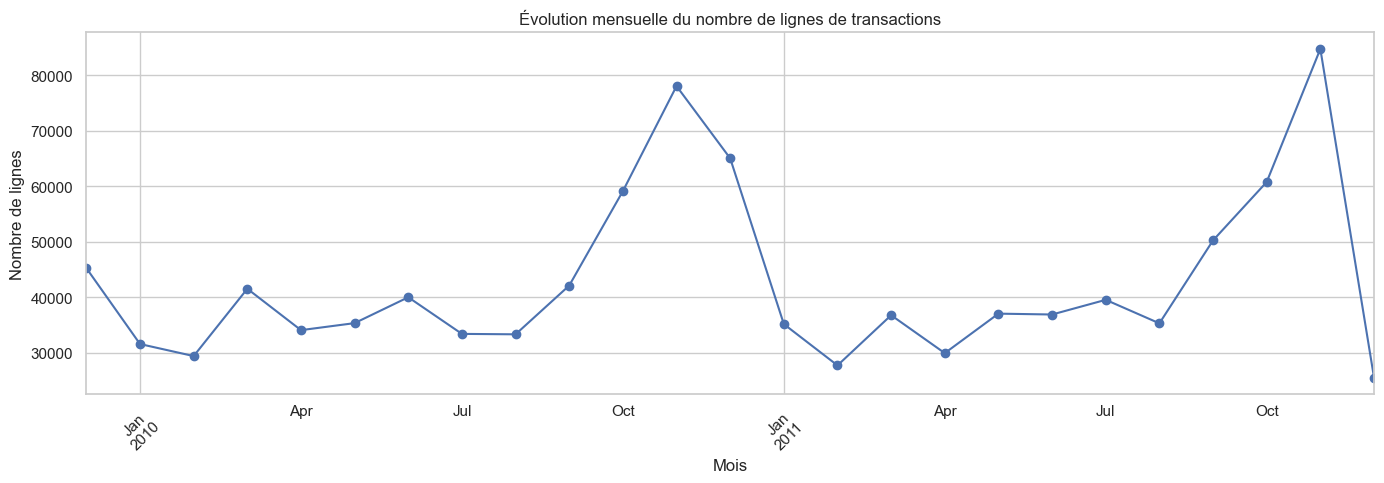

In [36]:
import matplotlib.pyplot as plt

# Nombre de lignes de transactions par mois
transactions_mensuelles = df.groupby("Mois").size()

plt.figure(figsize=(14, 5))

transactions_mensuelles.plot(kind="line", marker="o")

plt.title("Évolution mensuelle du nombre de lignes de transactions")
plt.xlabel("Mois")
plt.ylabel("Nombre de lignes")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

## 11. Synthèse du diagnostic initial

L'exploration du dataset Online Retail II a permis de mieux comprendre sa structure, son contenu et les principales particularités des données.

Le jeu de données contient initialement **1 067 371 lignes et 8 variables**, couvrant la période du 1er décembre 2009 au 9 décembre 2011.

Les principales observations sont les suivantes :

**1. Structure des données**
- 53 628 factures distinctes.
- 5 942 clients identifiés.
- 5 305 références produits.
- 43 pays représentés.
- Le Royaume-Uni concentre environ 91,94 % des lignes de transactions.

**2. Valeurs manquantes**
- `Customer ID` : 243 007 valeurs manquantes (22,77 %).
- `Description` : 4 382 valeurs manquantes (0,41 %).

L'absence d'identifiant client empêche d'attribuer certaines transactions à un client précis.

**3. Doublons**
- 34 335 lignes dupliquées exactement ont été détectées (3,22 %).
- Leur suppression simulée réduit le nombre de lignes à 1 033 036, sans modifier le nombre de factures ni de clients distincts.

La suppression sera appliquée pendant la phase de nettoyage.

**4. Anomalies et opérations particulières**
- Présence de quantités négatives correspondant notamment à des retours ou annulations.
- Présence de factures d'annulation identifiées par le préfixe `C`.
- Présence de prix négatifs et de montants inhabituels liés à des ajustements comptables.
- Présence de frais et d'opérations particulières qui ne correspondent pas à des ventes classiques.
- Certaines quantités élevées peuvent correspondre à des achats en gros et ne doivent pas être automatiquement supprimées.

**5. Analyse temporelle**

L'activité est particulièrement importante en octobre et novembre, avec un pic en novembre pour les deux années complètes observées.

**Conclusion**

Le dataset présente un potentiel intéressant pour une segmentation comportementale des clients. Cependant, plusieurs opérations particulières et valeurs manquantes nécessitent un traitement préalable.

La prochaine étape consistera à nettoyer les données, définir les transactions commerciales à retenir et construire une base fiable au niveau client pour l'analyse RFM et les algorithmes de clustering.